In [2]:
from google.colab import files

uploaded = files.upload()

Saving placement_data.csv to placement_data.csv


In [3]:
# ============================================
# ASSIGNMENT 2 - PLACEMENT ANALYTICS
# STEP 1: LOAD DATA
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

# Load dataset
df = pd.read_csv("placement_data.csv")

print("✅ Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

✅ Dataset loaded successfully!
Shape: (502, 10)


,Student_ID,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score,Placement_Status,Offer_Count,Salary
0,S1000,69.20,94.30,96.00,2.00,0,62.10,Placed,2,5.93
1,S1001,84.10,62.40,56.20,0.00,0,38.60,Placed,1,4.47
2,S1002,73.70,95.00,81.90,2.00,1,60.20,Placed,1,5.71
3,S1003,84.70,62.20,72.70,2.00,2,81.30,Placed,3,4.94
4,S1004,73.50,39.70,30.00,0.00,0,53.30,Not Placed,0,NaN


In [4]:
# ============================================
# STEP 2: INITIAL DATA INSPECTION
# ============================================

print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nPlacement Status:")
print(df["Placement_Status"].value_counts(dropna=False))

print("\nDataset Summary:")
display(df.describe(include="all"))

Column Names:
['Student_ID', 'Academic_Performance', 'Coding_Score', 'Project_Score', 'Certifications', 'Internships', 'Communication_Score', 'Placement_Status', 'Offer_Count', 'Salary']

Data Types:
Student_ID               object
Academic_Performance    float64
Coding_Score            float64
Project_Score           float64
Certifications          float64
Internships               int64
Communication_Score     float64
Placement_Status         object
Offer_Count               int64
Salary                  float64
dtype: object

Missing Values:
Student_ID                0
Academic_Performance      1
Coding_Score              1
Project_Score             0
Certifications            1
Internships               0
Communication_Score       0
Placement_Status          0
Offer_Count               0
Salary                  157
dtype: int64

Duplicate Rows:
2

Placement Status:
Placement_Status
Placed        344
Not Placed    156
placed          1
NOT PLACED      1
Name: count, dtype: int64

Da

,Student_ID,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score,Placement_Status,Offer_Count,Salary
count,502,501.00,501.00,502.00,501.00,502.00,502.00,502,502.00,345.00
unique,500,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN
top,S1100,NaN,NaN,NaN,NaN,NaN,NaN,Placed,NaN,NaN
freq,2,NaN,NaN,NaN,NaN,NaN,NaN,344,NaN,NaN
mean,NaN,72.21,62.59,63.06,1.48,0.85,63.93,NaN,1.12,5.22
std,NaN,8.97,18.48,15.46,1.34,0.86,15.14,NaN,1.05,1.67
min,NaN,47.90,11.30,21.30,0.00,0.00,-20.00,NaN,0.00,-5.00
25%,NaN,66.00,50.00,53.25,0.00,0.00,53.60,NaN,0.00,4.10
50%,NaN,72.80,62.40,62.50,1.00,1.00,64.00,NaN,1.00,5.22
75%,NaN,77.90,74.70,73.25,2.00,1.00,75.07,NaN,2.00,6.41


In [5]:
# ============================================
# STEP 3: DATA CLEANING & VALIDATION
# ============================================

print("Before cleaning:", df.shape)

# ------------------------------------------------
# 1. Remove exact duplicate rows
# ------------------------------------------------
df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

# ------------------------------------------------
# 2. Standardize Placement_Status
# ------------------------------------------------
df["Placement_Status"] = (
    df["Placement_Status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "placed": "Placed",
        "not placed": "Not Placed"
    })
)

# ------------------------------------------------
# 3. Convert numeric columns
# ------------------------------------------------
numeric_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score",
    "Offer_Count",
    "Salary"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------------
# 4. Validate score ranges (0-100)
# ------------------------------------------------
score_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Communication_Score"
]

for col in score_columns:
    df.loc[
        (df[col] < 0) | (df[col] > 100),
        col
    ] = np.nan

# ------------------------------------------------
# 5. Validate count variables
# ------------------------------------------------
count_columns = [
    "Certifications",
    "Internships",
    "Offer_Count"
]

for col in count_columns:
    df.loc[df[col] < 0, col] = np.nan

# ------------------------------------------------
# 6. Salary cannot be negative
# ------------------------------------------------
df.loc[df["Salary"] < 0, "Salary"] = np.nan

# ------------------------------------------------
# 7. Display invalid/missing values
# ------------------------------------------------
print("\nMissing values after validation:")
print(df.isnull().sum())

Before cleaning: (502, 10)
After removing duplicates: (500, 10)

Missing values after validation:
Student_ID                0
Academic_Performance      1
Coding_Score              2
Project_Score             0
Certifications            1
Internships               0
Communication_Score       1
Placement_Status          0
Offer_Count               0
Salary                  156
dtype: int64


In [6]:
# ============================================
# STEP 4: HANDLE MISSING VALUES
# ============================================

# Fill skill-score missing values with median
for col in score_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill certification/internship missing values with 0
for col in ["Certifications", "Internships"]:
    df[col] = df[col].fillna(0)

# Ensure Offer_Count is consistent with placement status
df.loc[
    df["Placement_Status"] == "Not Placed",
    "Offer_Count"
] = 0

# Students with no placement should not have a salary
df.loc[
    df["Placement_Status"] == "Not Placed",
    "Salary"
] = np.nan

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Student_ID                0
Academic_Performance      0
Coding_Score              0
Project_Score             0
Certifications            0
Internships               0
Communication_Score       0
Placement_Status          0
Offer_Count               0
Salary                  156
dtype: int64


In [7]:
# ============================================
# STEP 5: CREATE TARGET VARIABLE
# ============================================

df["Placed"] = (
    df["Placement_Status"] == "Placed"
).astype(int)

print("Placement distribution:")
print(df["Placement_Status"].value_counts())

print("\nPlacement percentage:")
print(
    (df["Placed"].value_counts(normalize=True) * 100)
    .round(2)
)

Placement distribution:
Placement_Status
Placed        345
Not Placed    155
Name: count, dtype: int64

Placement percentage:
Placed
1   69.00
0   31.00
Name: proportion, dtype: float64


In [8]:
# ============================================
# STEP 6: OFFER GROUPS
# ============================================

df["Offer_Group"] = pd.cut(
    df["Offer_Count"],
    bins=[-1, 0, 1, np.inf],
    labels=["None", "Single", "Multiple"]
)

print("Offer groups:")
print(df["Offer_Group"].value_counts())

display(
    df[
        [
            "Student_ID",
            "Placement_Status",
            "Offer_Count",
            "Offer_Group"
        ]
    ].head(10)
)

Offer groups:
Offer_Group
Single      202
None        155
Multiple    143
Name: count, dtype: int64


,Student_ID,Placement_Status,Offer_Count,Offer_Group
0,S1000,Placed,2.00,Multiple
1,S1001,Placed,1.00,Single
2,S1002,Placed,1.00,Single
3,S1003,Placed,3.00,Multiple
4,S1004,Not Placed,0.00,None
5,S1005,Placed,3.00,Multiple
6,S1006,Not Placed,0.00,None
7,S1007,Placed,1.00,Single
8,S1008,Placed,1.00,Single
9,S1009,Not Placed,0.00,None


In [9]:
# ============================================
# STEP 7: FINAL CLEANING CHECK
# ============================================

print("========== CLEANED DATA ==========")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nPlacement status:")
print(df["Placement_Status"].value_counts())

print("\nOffer groups:")
print(df["Offer_Group"].value_counts())

display(df.head())

========== CLEANED DATA ==========
Rows: 500
Columns: 12

Missing values:
Student_ID                0
Academic_Performance      0
Coding_Score              0
Project_Score             0
Certifications            0
Internships               0
Communication_Score       0
Placement_Status          0
Offer_Count               0
Salary                  156
Placed                    0
Offer_Group               0
dtype: int64

Duplicate rows:
0

Placement status:
Placement_Status
Placed        345
Not Placed    155
Name: count, dtype: int64

Offer groups:
Offer_Group
Single      202
None        155
Multiple    143
Name: count, dtype: int64


,Student_ID,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score,Placement_Status,Offer_Count,Salary,Placed,Offer_Group
0,S1000,69.20,94.30,96.00,2.00,0.00,62.10,Placed,2.00,5.93,1,Multiple
1,S1001,84.10,62.40,56.20,0.00,0.00,38.60,Placed,1.00,4.47,1,Single
2,S1002,73.70,95.00,81.90,2.00,1.00,60.20,Placed,1.00,5.71,1,Single
3,S1003,84.70,62.20,72.70,2.00,2.00,81.30,Placed,3.00,4.94,1,Multiple
4,S1004,73.50,39.70,30.00,0.00,0.00,53.30,Not Placed,0.00,NaN,0,None


In [10]:
# ============================================
# STEP 8: DESCRIPTIVE STATISTICS
# ============================================

analysis_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score",
    "Offer_Count",
    "Salary"
]

print("========== DESCRIPTIVE STATISTICS ==========")

display(
    df[analysis_columns]
    .describe()
    .round(2)
)

========== DESCRIPTIVE STATISTICS ==========


,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score,Offer_Count,Salary
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,344.00
mean,72.22,62.45,63.12,1.48,0.85,64.16,1.12,5.25
std,8.98,18.06,15.44,1.35,0.86,14.63,1.05,1.58
min,47.90,11.30,21.30,0.00,0.00,15.50,0.00,2.50
25%,66.00,50.00,53.35,0.00,0.00,53.82,0.00,4.12
50%,72.90,62.40,62.60,1.00,1.00,64.10,1.00,5.22
75%,77.90,74.62,73.30,2.00,1.00,75.15,2.00,6.41
max,98.00,100.00,100.00,6.00,3.00,100.00,6.00,10.52


In [11]:
# ============================================
# STEP 9: PLACEMENT SUCCESS
# ============================================

placement_rate = df["Placed"].mean()

print(
    f"Overall placement rate: {placement_rate:.2%}"
)

print("\nPlacement counts:")
print(df["Placement_Status"].value_counts())

Overall placement rate: 69.00%

Placement counts:
Placement_Status
Placed        345
Not Placed    155
Name: count, dtype: int64


In [12]:
# ============================================
# STEP 10: PLACED VS NOT PLACED
# ============================================

skill_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score"
]

comparison = (
    df.groupby("Placement_Status")[skill_columns]
    .mean()
    .T
    .round(2)
)

comparison["Gap"] = (
    comparison["Placed"] -
    comparison["Not Placed"]
).round(2)

print("========== PLACED VS NOT PLACED ==========")

display(
    comparison.sort_values(
        "Gap",
        ascending=False
    )
)

========== PLACED VS NOT PLACED ==========


Placement_Status,Not Placed,Placed,Gap
Coding_Score,50.85,67.66,16.81
Project_Score,56.27,66.20,9.93
Communication_Score,60.99,65.58,4.59
Academic_Performance,70.66,72.92,2.26
Certifications,1.04,1.67,0.63
Internships,0.59,0.97,0.38


In [13]:
# ============================================
# STEP 11: STATISTICAL SIGNIFICANCE
# ============================================

results = []

for col in skill_columns:

    placed_values = df.loc[
        df["Placed"] == 1, col
    ]

    not_placed_values = df.loc[
        df["Placed"] == 0, col
    ]

    statistic, p_value = stats.mannwhitneyu(
        placed_values,
        not_placed_values,
        alternative="two-sided"
    )

    results.append([
        col,
        p_value
    ])

test_results = pd.DataFrame(
    results,
    columns=["Feature", "P_Value"]
)

test_results["Significant"] = np.where(
    test_results["P_Value"] < 0.05,
    "Yes",
    "No"
)

display(
    test_results.sort_values("P_Value")
)

,Feature,P_Value,Significant
1,Coding_Score,0.00,Yes
2,Project_Score,0.00,Yes
3,Certifications,0.00,Yes
4,Internships,0.00,Yes
5,Communication_Score,0.00,Yes
0,Academic_Performance,0.00,Yes


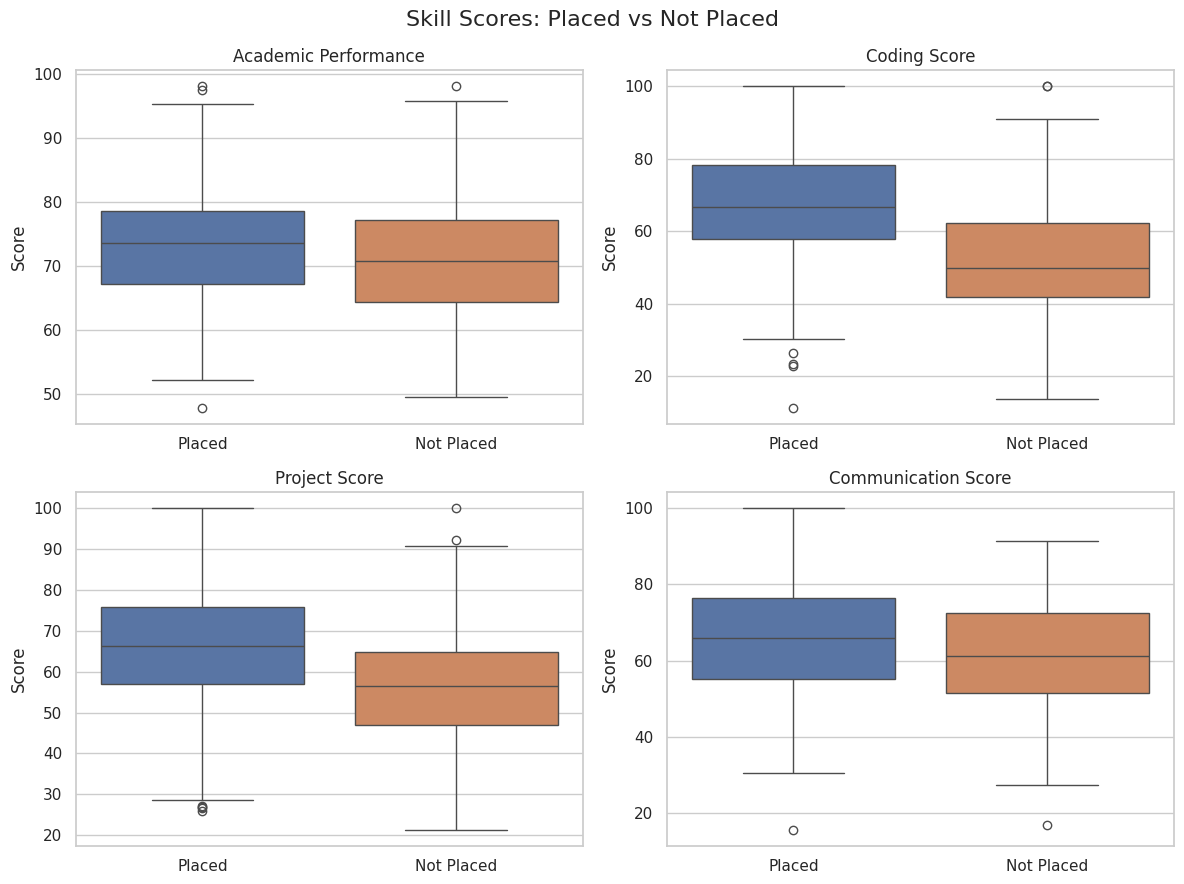

In [14]:
# ============================================
# VISUALISATION 1
# ============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9)
)

score_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Communication_Score"
]

for ax, col in zip(
    axes.flatten(),
    score_columns
):

    sns.boxplot(
        data=df,
        x="Placement_Status",
        y=col,
        hue="Placement_Status",
        legend=False,
        ax=ax
    )

    ax.set_title(
        col.replace("_", " ")
    )

    ax.set_xlabel("")
    ax.set_ylabel("Score")

plt.suptitle(
    "Skill Scores: Placed vs Not Placed",
    fontsize=16
)

plt.tight_layout()
plt.show()

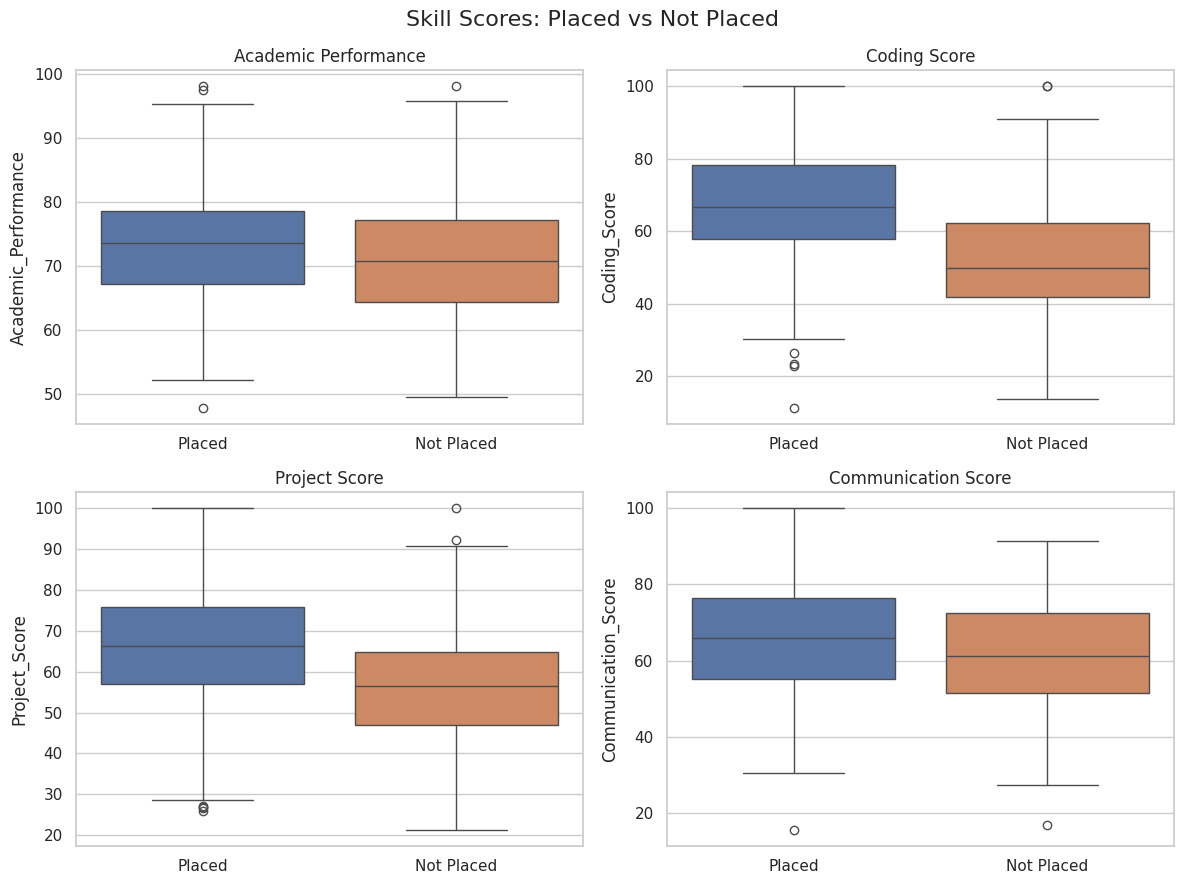

In [15]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9)
)

for ax, col in zip(
    axes.flatten(),
    score_columns
):

    sns.boxplot(
        data=df,
        x="Placement_Status",
        y=col,
        hue="Placement_Status",
        legend=False,
        ax=ax
    )

    ax.set_title(
        col.replace("_", " ")
    )

    ax.set_xlabel("")

plt.suptitle(
    "Skill Scores: Placed vs Not Placed",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "viz1_scores_by_placement.png",
    dpi=300
)

plt.show()

In [16]:
# Compare students with multiple offers vs no offers

offer_comparison = df[df["Offer_Group"].isin(["None", "Multiple"])].groupby("Offer_Group")[
    ["Academic_Performance", "Coding_Score", "Project_Score",
     "Certifications", "Internships", "Communication_Score"]
].mean().round(2)

display(offer_comparison)

/tmp/ipykernel_2179/2883424160.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  offer_comparison = df[df["Offer_Group"].isin(["None", "Multiple"])].groupby("Offer_Group")[


,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score
Offer_Group,,,,,,
None,70.66,50.85,56.27,1.04,0.59,60.99
Single,NaN,NaN,NaN,NaN,NaN,NaN
Multiple,73.48,72.93,69.20,1.68,1.26,65.24


In [17]:
multiple = offer_comparison.loc["Multiple"]
none = offer_comparison.loc["None"]

offer_gaps = (multiple - none).round(2)

print("Difference: Multiple Offers - No Offers")
display(offer_gaps.to_frame("Difference"))

Difference: Multiple Offers - No Offers


,Difference
Academic_Performance,2.82
Coding_Score,22.08
Project_Score,12.93
Certifications,0.64
Internships,0.67
Communication_Score,4.25


<Figure size 1000x600 with 0 Axes>

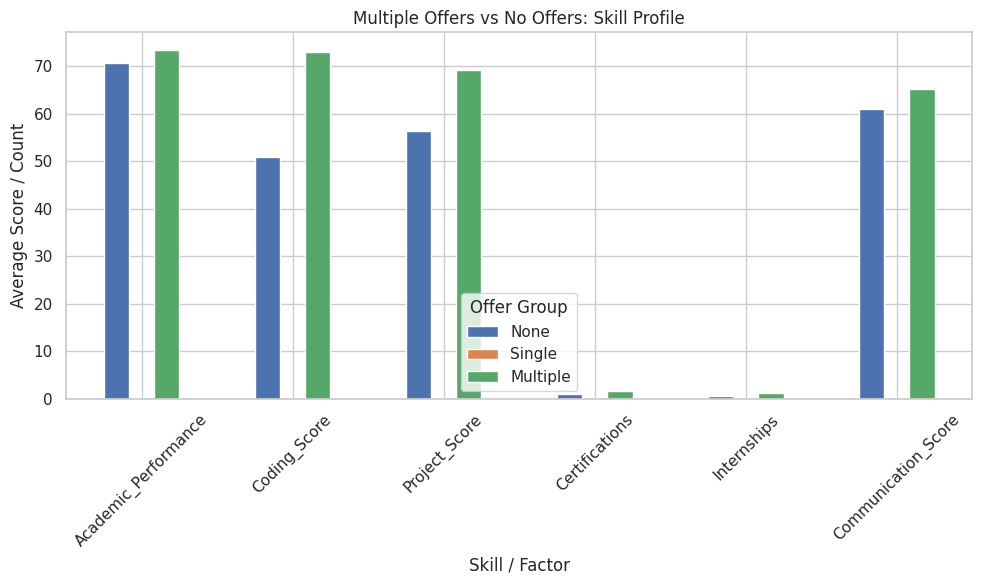

In [18]:
plt.figure(figsize=(10, 6))

offer_comparison.T.plot(kind="bar", figsize=(10, 6))

plt.title("Multiple Offers vs No Offers: Skill Profile")
plt.ylabel("Average Score / Count")
plt.xlabel("Skill / Factor")
plt.xticks(rotation=45)
plt.legend(title="Offer Group")
plt.tight_layout()

plt.savefig("viz2_multiple_offers_vs_none.png", dpi=300)
plt.show()

In [19]:
# Keep only placed students with valid salary values

placed_salary = df[
    (df["Placement_Status"] == "Placed") &
    (df["Salary"].notna())
].copy()

print("Number of placed students with salary data:", len(placed_salary))

display(
    placed_salary[
        ["Coding_Score", "Salary"]
    ].describe().round(2)
)

Number of placed students with salary data: 344


,Coding_Score,Salary
count,344.00,344.00
mean,67.73,5.25
std,16.60,1.58
min,11.30,2.50
25%,58.08,4.12
50%,66.80,5.22
75%,78.20,6.41
max,100.00,10.52


In [20]:
from scipy import stats

pearson_r, pearson_p = stats.pearsonr(
    placed_salary["Coding_Score"],
    placed_salary["Salary"]
)

spearman_r, spearman_p = stats.spearmanr(
    placed_salary["Coding_Score"],
    placed_salary["Salary"]
)

print(f"Pearson correlation:  {pearson_r:.3f}")
print(f"Pearson p-value:      {pearson_p:.4f}")
print()
print(f"Spearman correlation: {spearman_r:.3f}")
print(f"Spearman p-value:     {spearman_p:.4f}")

Pearson correlation:  0.745
Pearson p-value:      0.0000

Spearman correlation: 0.754
Spearman p-value:     0.0000


In [21]:
slope, intercept, r_value, p_value, std_err = stats.linregress(
    placed_salary["Coding_Score"],
    placed_salary["Salary"]
)

print(f"Regression equation:")
print(f"Salary = {intercept:.2f} + ({slope:.2f} × Coding Score)")
print(f"R² = {r_value**2:.3f}")
print(f"p-value = {p_value:.4f}")

Regression equation:
Salary = 0.45 + (0.07 × Coding Score)
R² = 0.555
p-value = 0.0000


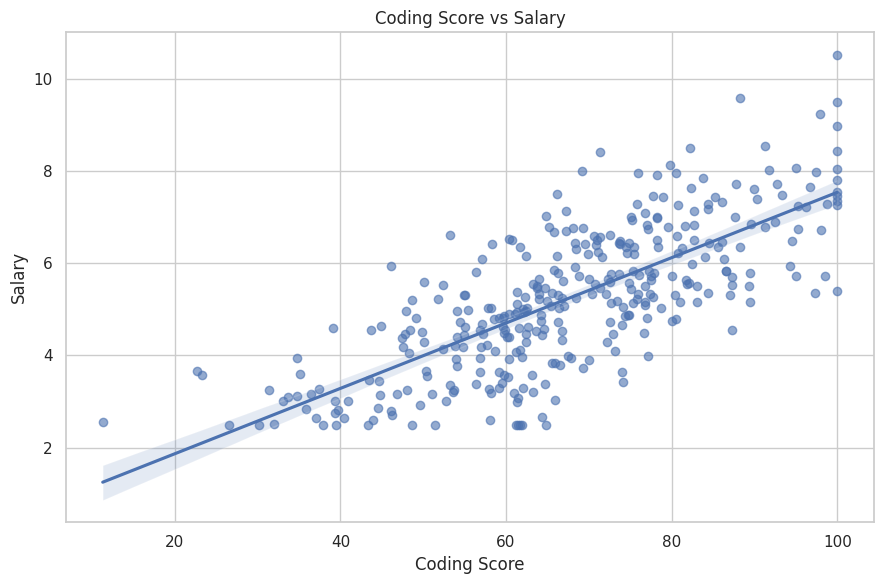

In [22]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=placed_salary,
    x="Coding_Score",
    y="Salary",
    scatter_kws={"alpha": 0.6},
    line_kws={}
)

plt.title("Coding Score vs Salary")
plt.xlabel("Coding Score")
plt.ylabel("Salary")
plt.tight_layout()

plt.savefig("viz3_coding_vs_salary.png", dpi=300)
plt.show()

In [23]:
# Divide students into Low, Mid, and High academic-performance groups

df["Acad_Band"] = pd.qcut(
    df["Academic_Performance"],
    q=3,
    labels=["Low", "Mid", "High"],
    duplicates="drop"
)

display(
    df.groupby("Acad_Band", observed=True)["Academic_Performance"]
      .agg(["min", "max", "mean", "count"])
      .round(2)
)

,min,max,mean,count
Acad_Band,,,,
Low,47.90,68.40,62.31,167
Mid,68.50,75.80,72.57,166
High,75.90,98.00,81.78,167


In [24]:
df["Cert_Group"] = np.where(
    df["Certifications"] >= 2,
    "2+ certs",
    "0-1 certs"
)

cert_summary = df.groupby("Cert_Group").agg(
    Students=("Student_ID", "count"),
    Placement_Rate=("Placed", "mean"),
    Avg_Academic=("Academic_Performance", "mean"),
    Avg_Coding=("Coding_Score", "mean"),
    Avg_Salary=("Salary", "mean")
).round(2)

cert_summary["Placement_Rate"] = (
    cert_summary["Placement_Rate"] * 100
).round(2)

display(cert_summary)

,Students,Placement_Rate,Avg_Academic,Avg_Coding,Avg_Salary
Cert_Group,,,,,
0-1 certs,289,60.00,72.43,58.46,4.66
2+ certs,211,82.00,71.92,67.92,5.84


In [25]:
cert_academic = df.groupby(
    ["Acad_Band", "Cert_Group"],
    observed=True
).agg(
    Students=("Student_ID", "count"),
    Placement_Rate=("Placed", "mean"),
    Avg_Coding=("Coding_Score", "mean")
).reset_index()

cert_academic["Placement_Rate"] = (
    cert_academic["Placement_Rate"] * 100
).round(2)

display(cert_academic)

,Acad_Band,Cert_Group,Students,Placement_Rate,Avg_Coding
0,Low,0-1 certs,91,43.96,54.94
1,Low,2+ certs,76,82.89,66.72
2,Mid,0-1 certs,99,62.63,57.64
3,Mid,2+ certs,67,82.09,70.73
4,High,0-1 certs,99,71.72,62.52
5,High,2+ certs,68,79.41,66.48


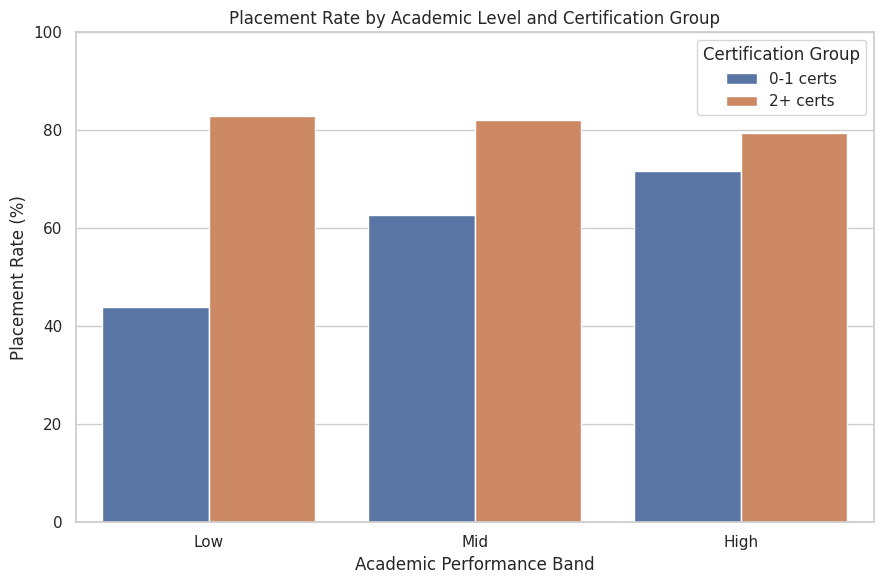

In [26]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=cert_academic,
    x="Acad_Band",
    y="Placement_Rate",
    hue="Cert_Group"
)

plt.title("Placement Rate by Academic Level and Certification Group")
plt.xlabel("Academic Performance Band")
plt.ylabel("Placement Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Certification Group")
plt.tight_layout()

plt.savefig("viz4_certifications_by_academic_band.png", dpi=300)
plt.show()

In [27]:
placed_cert = df[
    (df["Placement_Status"] == "Placed") &
    (df["Salary"].notna())
]

salary_by_cert = placed_cert.groupby("Cert_Group")["Salary"].agg(
    ["count", "mean", "median"]
).round(2)

display(salary_by_cert)

,count,mean,median
Cert_Group,,,
0-1 certs,172,4.66,4.62
2+ certs,172,5.84,5.76


In [28]:
# Create skill profiles

df["Profile"] = np.select(
    [
        (df["Coding_Score"] >= 70) &
        (df["Communication_Score"] >= 65),

        (df["Coding_Score"] >= 70),

        (df["Communication_Score"] >= 70)
    ],
    [
        "Technical + Communicator",
        "Technical-strong",
        "Communicator-strong"
    ],
    default="Developing"
)

profile_summary = df.groupby("Profile").agg(
    Students=("Student_ID", "count"),
    Placement_Rate=("Placed", "mean"),
    Avg_Coding=("Coding_Score", "mean"),
    Avg_Communication=("Communication_Score", "mean"),
    Avg_Project=("Project_Score", "mean"),
    Avg_Certifications=("Certifications", "mean"),
    Avg_Internships=("Internships", "mean")
).round(2)

profile_summary["Placement_Rate"] = (
    profile_summary["Placement_Rate"] * 100
).round(2)

display(profile_summary)

,Students,Placement_Rate,Avg_Coding,Avg_Communication,Avg_Project,Avg_Certifications,Avg_Internships
Profile,,,,,,,
Communicator-strong,102,62.00,51.42,80.62,59.28,1.13,0.83
Developing,227,56.00,52.83,56.05,58.70,1.26,0.74
Technical + Communicator,88,92.00,81.71,76.73,71.06,1.93,0.94
Technical-strong,83,89.00,81.90,52.77,71.54,2.00,1.08


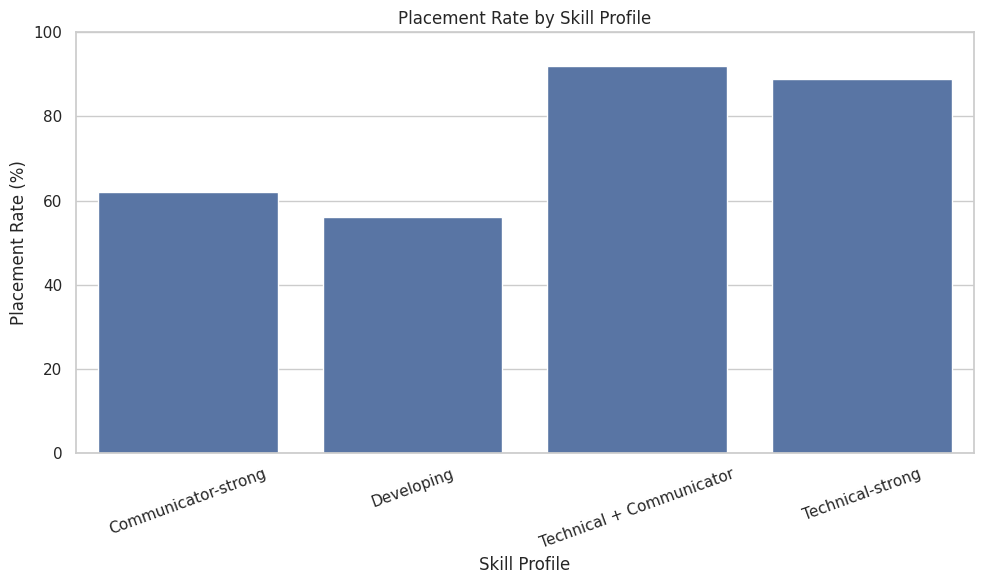

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=profile_summary.reset_index(),
    x="Profile",
    y="Placement_Rate"
)

plt.title("Placement Rate by Skill Profile")
plt.xlabel("Skill Profile")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig("viz5_skill_profiles.png", dpi=300)
plt.show()

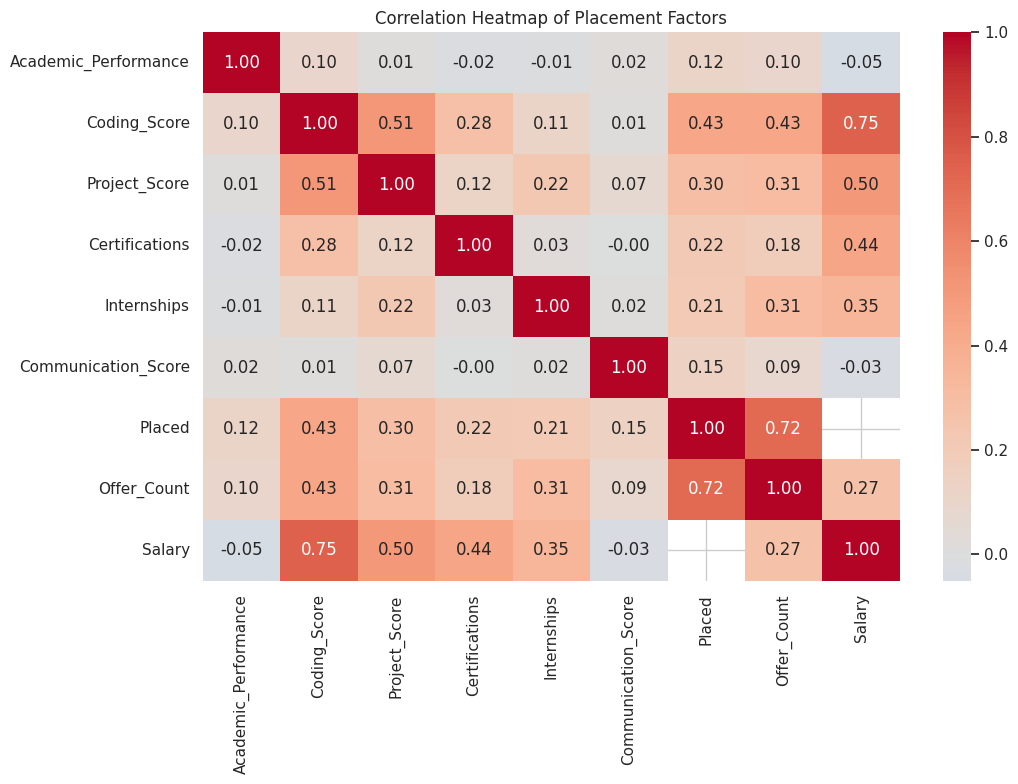

In [30]:
corr_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score",
    "Placed",
    "Offer_Count",
    "Salary"
]

correlation_matrix = df[corr_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Placement Factors")
plt.tight_layout()

plt.savefig("viz6_correlation_heatmap.png", dpi=300)
plt.show()

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

features = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score"
]

X = df[features]
y = df["Placed"]

print("Features:")
print(features)

print("\nTarget:")
print("Placed")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['Academic_Performance', 'Coding_Score', 'Project_Score', 'Certifications', 'Internships', 'Communication_Score']

Target:
Placed

X shape: (500, 6)
y shape: (500,)


In [32]:
print("Target distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Target distribution:
Placed
1    345
0    155
Name: count, dtype: int64

Target percentage:
Placed
1   69.00
0   31.00
Name: proportion, dtype: float64


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 375
Testing samples: 125


In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [35]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!

First 10 predictions:
[0 1 1 1 1 1 1 1 0 1]


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy :  {accuracy:.3f}")
print(f"Precision:  {precision:.3f}")
print(f"Recall   :  {recall:.3f}")
print(f"F1 Score :  {f1:.3f}")
print(f"ROC-AUC  :  {auc:.3f}")

Accuracy :  0.744
Precision:  0.829
Recall   :  0.791
F1 Score :  0.810
ROC-AUC  :  0.838


In [37]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Placed", "Placed"]
))

              precision    recall  f1-score   support

  Not Placed       0.58      0.64      0.61        39
      Placed       0.83      0.79      0.81        86

    accuracy                           0.74       125
   macro avg       0.71      0.72      0.71       125
weighted avg       0.75      0.74      0.75       125



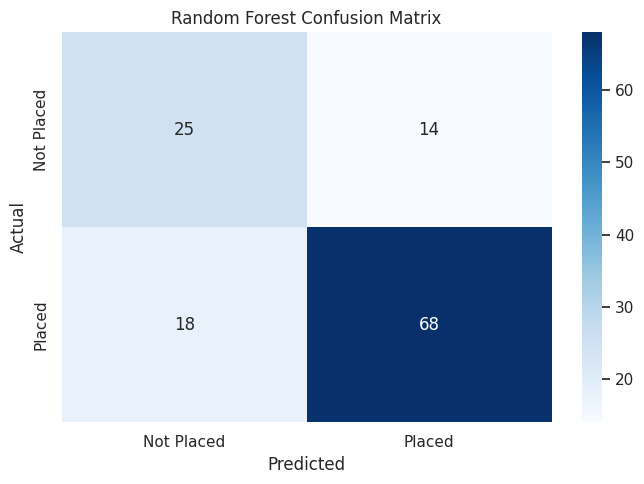

In [38]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig("rf_confusion_matrix.png", dpi=300)
plt.show()

In [39]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_auc = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("AUC scores for each fold:")
print(np.round(cv_auc, 3))

print("\nMean CV AUC:", round(cv_auc.mean(), 3))
print("Standard deviation:", round(cv_auc.std(), 3))

AUC scores for each fold:
[0.797 0.836 0.751 0.847 0.821]

Mean CV AUC: 0.81
Standard deviation: 0.034


In [40]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

feature_importance["Importance"] = (
    feature_importance["Importance"] * 100
).round(2)

display(feature_importance)

,Feature,Importance
1,Coding_Score,41.37
2,Project_Score,15.13
0,Academic_Performance,14.50
5,Communication_Score,13.63
3,Certifications,8.31
4,Internships,7.07


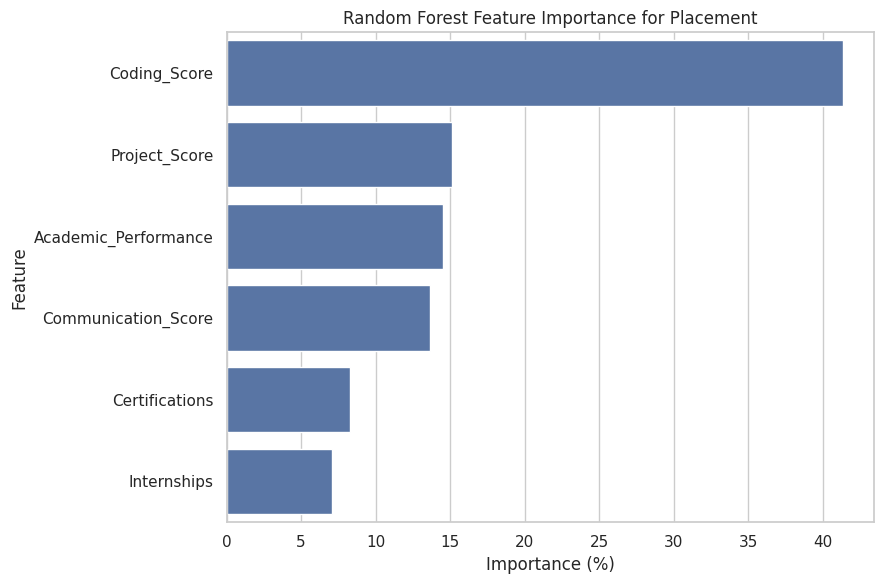

In [41]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance for Placement")
plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig("rf_feature_importance.png", dpi=300)
plt.show()

In [42]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

permutation_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance_Mean": perm.importances_mean,
    "Importance_STD": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(permutation_importance_df.round(4))

,Feature,Importance_Mean,Importance_STD
1,Coding_Score,0.19,0.04
2,Project_Score,0.03,0.01
3,Certifications,0.02,0.01
4,Internships,0.02,0.01
0,Academic_Performance,0.01,0.01
5,Communication_Score,-0.00,0.01


In [43]:
# Compare unplaced students with students receiving multiple offers

skill_columns = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score"
]

skill_gap = df.groupby("Offer_Group", observed=True)[skill_columns].mean().round(2)

display(skill_gap)


,Academic_Performance,Coding_Score,Project_Score,Certifications,Internships,Communication_Score
Offer_Group,,,,,,
None,70.66,50.85,56.27,1.04,0.59,60.99
Single,72.52,63.94,64.08,1.67,0.77,65.83
Multiple,73.48,72.93,69.20,1.68,1.26,65.24


In [44]:
coding_bands = pd.cut(
    df["Coding_Score"],
    bins=[-1, 40, 55, 70, 85, 100],
    labels=["0-40", "41-55", "56-70", "71-85", "86-100"]
)

coding_placement = df.groupby(
    coding_bands,
    observed=True
)["Placed"].agg(["count", "mean"])

coding_placement["Placement_Rate"] = (
    coding_placement["mean"] * 100
).round(2)

coding_placement = coding_placement.drop(columns="mean")

display(coding_placement)

,count,Placement_Rate
Coding_Score,,
0-40,58,37.93
41-55,110,46.36
56-70,165,72.12
71-85,111,90.99
86-100,56,92.86


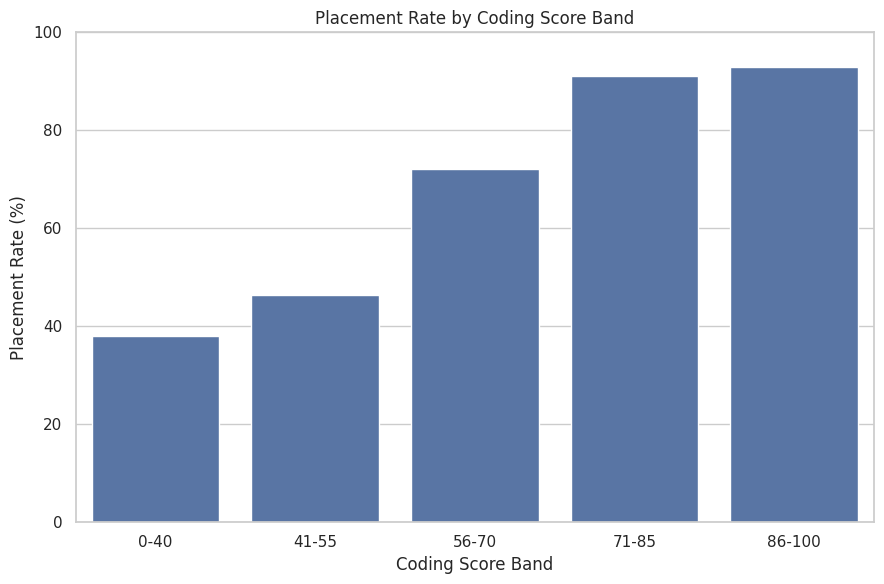

In [45]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=coding_placement.reset_index(),
    x="Coding_Score",
    y="Placement_Rate"
)

plt.title("Placement Rate by Coding Score Band")
plt.xlabel("Coding Score Band")
plt.ylabel("Placement Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig("coding_band_placement.png", dpi=300)
plt.show()

In [46]:
df.to_csv("placement_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset saved successfully!
Rows: 500
Columns: 15


In [47]:
model_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Mean CV AUC",
        "CV AUC Std"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        auc,
        cv_auc.mean(),
        cv_auc.std()
    ]
})

model_results["Value"] = model_results["Value"].round(3)

display(model_results)

model_results.to_csv("placement_model_results.csv", index=False)

,Metric,Value
0,Accuracy,0.74
1,Precision,0.83
2,Recall,0.79
3,F1 Score,0.81
4,ROC-AUC,0.84
5,Mean CV AUC,0.81
6,CV AUC Std,0.03


In [48]:
import os

files_to_check = [
    "placement_cleaned.csv",
    "placement_model_results.csv",
    "viz1_scores_by_placement.png",
    "viz2_multiple_offers_vs_none.png",
    "viz3_coding_vs_salary.png",
    "viz4_certifications_by_academic_band.png",
    "viz5_skill_profiles.png",
    "viz6_correlation_heatmap.png",
    "rf_confusion_matrix.png",
    "rf_feature_importance.png",
    "coding_band_placement.png"
]

for file in files_to_check:
    print(f"{file}: {'✓ Found' if os.path.exists(file) else '✗ Missing'}")

placement_cleaned.csv: ✓ Found
placement_model_results.csv: ✓ Found
viz1_scores_by_placement.png: ✓ Found
viz2_multiple_offers_vs_none.png: ✓ Found
viz3_coding_vs_salary.png: ✓ Found
viz4_certifications_by_academic_band.png: ✓ Found
viz5_skill_profiles.png: ✓ Found
viz6_correlation_heatmap.png: ✓ Found
rf_confusion_matrix.png: ✓ Found
rf_feature_importance.png: ✓ Found
coding_band_placement.png: ✓ Found


In [49]:
final_summary = {
    "Total Students": len(df),
    "Placed Students": int(df["Placed"].sum()),
    "Not Placed Students": int((df["Placed"] == 0).sum()),
    "Overall Placement Rate (%)": round(df["Placed"].mean() * 100, 2),
    "Test Accuracy (%)": round(accuracy * 100, 2),
    "Test Precision (%)": round(precision * 100, 2),
    "Test Recall (%)": round(recall * 100, 2),
    "Test F1 Score (%)": round(f1 * 100, 2),
    "Test ROC-AUC": round(auc, 3),
    "Mean CV ROC-AUC": round(cv_auc.mean(), 3)
}

final_summary_df = pd.DataFrame(
    final_summary.items(),
    columns=["Metric", "Value"]
)

display(final_summary_df)

,Metric,Value
0,Total Students,500.00
1,Placed Students,345.00
2,Not Placed Students,155.00
3,Overall Placement Rate (%),69.00
4,Test Accuracy (%),74.40
5,Test Precision (%),82.93
6,Test Recall (%),79.07
7,Test F1 Score (%),80.95
8,Test ROC-AUC,0.84
9,Mean CV ROC-AUC,0.81


In [50]:
top_features = feature_importance.head(3)

print("Top 3 predictive factors:")
display(top_features)

Top 3 predictive factors:


,Feature,Importance
1,Coding_Score,41.37
2,Project_Score,15.13
0,Academic_Performance,14.50


In [51]:
# Calculate placed vs not-placed averages

placed_means = df[df["Placed"] == 1][skill_columns].mean()
not_placed_means = df[df["Placed"] == 0][skill_columns].mean()

comparison = pd.DataFrame({
    "Placed": placed_means,
    "Not Placed": not_placed_means
})

comparison["Difference"] = (
    comparison["Placed"] - comparison["Not Placed"]
).round(2)

comparison = comparison.sort_values(
    "Difference",
    ascending=False
)

display(comparison.round(2))

,Placed,Not Placed,Difference
Coding_Score,67.66,50.85,16.81
Project_Score,66.20,56.27,9.93
Communication_Score,65.58,60.99,4.60
Academic_Performance,72.92,70.66,2.26
Certifications,1.67,1.04,0.63
Internships,0.97,0.59,0.38


In [52]:
final_insights = pd.DataFrame({
    "Analysis": [
        "Overall Placement",
        "Multiple Offers",
        "Coding vs Salary",
        "Certifications",
        "Skill Profiles",
        "Random Forest",
        "Top Predictive Factor"
    ],
    "Result": [
        f"{df['Placed'].mean()*100:.2f}% students were placed.",
        "Compare Multiple vs None using the offer comparison table.",
        f"Pearson correlation = {pearson_r:.3f}.",
        "Compare 2+ certifications with 0-1 certifications.",
        "Compare placement rates across skill profiles.",
        f"ROC-AUC = {auc:.3f}.",
        feature_importance.iloc[0]["Feature"]
    ]
})

display(final_insights)

,Analysis,Result
0,Overall Placement,69.00% students were placed.
1,Multiple Offers,Compare Multiple vs None using the offer compa...
2,Coding vs Salary,Pearson correlation = 0.745.
3,Certifications,Compare 2+ certifications with 0-1 certificati...
4,Skill Profiles,Compare placement rates across skill profiles.
5,Random Forest,ROC-AUC = 0.838.
6,Top Predictive Factor,Coding_Score


In [54]:
import pandas as pd
import numpy as np
import json
from google.colab import files

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv("placement_data.csv")

# ============================================================
# CLEAN DATA
# ============================================================

df = df.drop_duplicates().copy()

df["Placement_Status"] = (
    df["Placement_Status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "placed": "Placed",
        "not placed": "Not Placed"
    })
)

scores = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Communication_Score"
]

counts = [
    "Certifications",
    "Internships",
    "Offer_Count"
]

for col in scores + counts + ["Salary"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in scores:
    df.loc[
        (df[col] < 0) | (df[col] > 100),
        col
    ] = np.nan

for col in counts + ["Salary"]:
    df.loc[df[col] < 0, col] = np.nan

df = df.dropna(subset=["Placement_Status"])

for col in scores:
    df[col] = df[col].fillna(df[col].median())

for col in ["Certifications", "Internships"]:
    df[col] = df[col].fillna(0)

df.loc[
    df["Placement_Status"] == "Not Placed",
    "Offer_Count"
] = 0

df.loc[
    df["Placement_Status"] == "Not Placed",
    "Salary"
] = np.nan

df["Placed"] = (
    df["Placement_Status"] == "Placed"
).astype(int)

# ============================================================
# BASIC METRICS
# ============================================================

total_students = len(df)

placed_students = int(df["Placed"].sum())

not_placed_students = (
    total_students - placed_students
)

placement_rate = round(
    placed_students / total_students * 100,
    2
)

placed_salary = df[
    (df["Placed"] == 1) &
    (df["Salary"].notna())
]["Salary"]

average_salary = round(
    placed_salary.mean(),
    2
)

multiple_offers = int(
    (df["Offer_Count"] >= 2).sum()
)

# ============================================================
# ACADEMIC ANALYSIS
# ============================================================

df["Academic_Band"] = pd.qcut(
    df["Academic_Performance"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

academic_data = (
    df.groupby(
        "Academic_Band",
        observed=True
    )["Placed"]
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

# ============================================================
# CODING ANALYSIS
# ============================================================

df["Coding_Band"] = pd.cut(
    df["Coding_Score"],
    bins=[-1, 40, 55, 70, 85, 100],
    labels=[
        "0-40",
        "41-55",
        "56-70",
        "71-85",
        "86-100"
    ]
)

coding_data = (
    df.groupby(
        "Coding_Band",
        observed=True
    )["Placed"]
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

# ============================================================
# CERTIFICATION ANALYSIS
# ============================================================

df["Certification_Group"] = np.where(
    df["Certifications"] >= 2,
    "2+ Certifications",
    "0-1 Certifications"
)

cert_data = (
    df.groupby(
        "Certification_Group"
    )["Placed"]
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

# ============================================================
# SKILL PROFILE
# ============================================================

df["Skill_Profile"] = np.select(
    [
        (df["Coding_Score"] >= 70) &
        (df["Communication_Score"] >= 65),

        df["Coding_Score"] >= 70,

        df["Communication_Score"] >= 70
    ],

    [
        "Technical + Communicator",
        "Technical Strong",
        "Communicator Strong"
    ],

    default="Developing"
)

profile_data = (
    df.groupby(
        "Skill_Profile"
    )["Placed"]
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

# ============================================================
# OFFER ANALYSIS
# ============================================================

df["Offer_Group"] = pd.cut(
    df["Offer_Count"],
    bins=[-1, 0, 1, np.inf],
    labels=[
        "No Offers",
        "Single Offer",
        "Multiple Offers"
    ]
)

offer_data = (
    df.groupby(
        "Offer_Group",
        observed=True
    )["Placed"]
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

# ============================================================
# CODING VS SALARY
# ============================================================

salary_data = df[
    (df["Placed"] == 1) &
    (df["Salary"].notna())
]

coding_salary_corr = round(
    salary_data["Coding_Score"].corr(
        salary_data["Salary"]
    ),
    3
)

# ============================================================
# FEATURE IMPORTANCE
# ============================================================

features = [
    "Academic_Performance",
    "Coding_Score",
    "Project_Score",
    "Certifications",
    "Internships",
    "Communication_Score"
]

corr = (
    df[features + ["Placed"]]
    .corr()["Placed"]
    .drop("Placed")
    .abs()
    .sort_values(ascending=False)
)

feature_data = {
    k: round(
        float(v / corr.sum() * 100),
        2
    )
    for k, v in corr.items()
}

# ============================================================
# JSON DATA
# ============================================================

data = {
    "total": total_students,
    "placed": placed_students,
    "notPlaced": not_placed_students,
    "placementRate": placement_rate,
    "averageSalary": average_salary,
    "multipleOffers": multiple_offers,
    "academic": academic_data,
    "coding": coding_data,
    "certifications": cert_data,
    "profiles": profile_data,
    "offers": offer_data,
    "correlation": coding_salary_corr,
    "features": feature_data
}

data_json = json.dumps(data)

# ============================================================
# HTML
# ============================================================

html = f"""
<!DOCTYPE html>

<html>

<head>

<meta charset="UTF-8">

<meta name="viewport"
content="width=device-width, initial-scale=1.0">

<title>Placement Analytics Dashboard</title>

<style>

* {{
    box-sizing: border-box;
}}

body {{
    margin: 0;
    font-family: Arial, Helvetica, sans-serif;
    background: #f4f7fb;
    color: #172033;
}}

/* SIDEBAR */

.sidebar {{
    position: fixed;
    left: 0;
    top: 0;

    width: 250px;
    height: 100vh;

    background: #111827;

    color: white;

    padding: 28px 16px;
}}

.logo {{
    font-size: 25px;
    font-weight: bold;
    margin-bottom: 5px;
}}

.subtitle {{
    color: #9ca3af;
    font-size: 13px;
    margin-bottom: 30px;
}}

.nav button {{
    width: 100%;

    border: none;

    background: transparent;

    color: #d1d5db;

    padding: 13px;

    margin: 4px 0;

    border-radius: 9px;

    text-align: left;

    font-size: 14px;

    cursor: pointer;
}}

.nav button:hover,
.nav button.active {{
    background: #2563eb;
    color: white;
}}

/* MAIN */

.main {{
    margin-left: 250px;

    padding: 32px;
}}

.header {{
    display: flex;

    justify-content: space-between;

    align-items: center;

    margin-bottom: 28px;
}}

.header h1 {{
    margin: 0;

    font-size: 31px;
}}

.header p {{
    color: #64748b;

    margin-top: 8px;
}}

.badge {{
    background: #dbeafe;

    color: #1d4ed8;

    padding: 9px 16px;

    border-radius: 20px;

    font-size: 12px;

    font-weight: bold;
}}

/* CARDS */

.cards {{
    display: grid;

    grid-template-columns:
    repeat(4, 1fr);

    gap: 18px;

    margin-bottom: 22px;
}}

.card {{
    background: white;

    border-radius: 16px;

    padding: 23px;

    box-shadow:
    0 5px 20px rgba(0,0,0,0.06);
}}

.card-title {{
    color: #64748b;

    font-size: 13px;
}}

.card-value {{
    font-size: 30px;

    font-weight: bold;

    margin-top: 10px;

    color: #111827;
}}

.card-small {{
    font-size: 12px;

    color: #94a3b8;

    margin-top: 6px;
}}

/* PANELS */

.grid {{
    display: grid;

    grid-template-columns:
    1fr 1fr;

    gap: 20px;

    margin-bottom: 20px;
}}

.panel {{
    background: white;

    border-radius: 16px;

    padding: 22px;

    box-shadow:
    0 5px 20px rgba(0,0,0,0.06);
}}

.panel h2 {{
    margin: 0 0 5px;

    font-size: 19px;
}}

.description {{
    color: #64748b;

    font-size: 12px;

    margin-bottom: 20px;
}}

/* SECTIONS */

.section {{
    display: none;
}}

.section.active {{
    display: block;
}}

/* DONUT */

.donut-container {{
    display: flex;

    align-items: center;

    justify-content: center;

    gap: 35px;

    height: 280px;
}}

.donut {{
    width: 190px;

    height: 190px;

    border-radius: 50%;

    background:
    conic-gradient(
        #2563eb 0deg,
        #2563eb var(--angle),
        #e5e7eb var(--angle),
        #e5e7eb 360deg
    );

    position: relative;
}}

.donut::after {{
    content: "";

    position: absolute;

    width: 110px;

    height: 110px;

    background: white;

    border-radius: 50%;

    top: 40px;

    left: 40px;
}}

.donut-center {{
    position: absolute;

    z-index: 2;

    top: 75px;

    left: 0;

    width: 100%;

    text-align: center;

    font-size: 23px;

    font-weight: bold;
}}

.legend div {{
    margin: 12px 0;

    font-size: 13px;
}}

.dot {{
    width: 11px;

    height: 11px;

    border-radius: 50%;

    display: inline-block;

    margin-right: 7px;
}}

.blue {{
    background: #2563eb;
}}

.gray {{
    background: #e5e7eb;
}}

/* BAR CHART */

.bar-chart {{
    height: 280px;

    display: flex;

    align-items: flex-end;

    justify-content: space-around;

    gap: 15px;

    padding:
    20px 10px 35px;
}}

.bar-wrapper {{
    height: 100%;

    flex: 1;

    display: flex;

    flex-direction: column;

    justify-content: flex-end;

    align-items: center;
}}

.bar {{
    width: 55px;

    max-width: 80%;

    background: #2563eb;

    border-radius:
    7px 7px 0 0;

    min-height: 3px;

    transition: .3s;
}}

.bar:hover {{
    background: #1d4ed8;

    transform:
    translateY(-3px);
}}

.bar-value {{
    font-size: 12px;

    font-weight: bold;

    margin-bottom: 5px;
}}

.bar-label {{
    font-size: 11px;

    color: #64748b;

    margin-top: 8px;

    text-align: center;
}}

/* INSIGHTS */

.insights {{
    display: grid;

    grid-template-columns:
    1fr 1fr;

    gap: 15px;
}}

.insight {{
    background: #f8fafc;

    padding: 18px;

    border-left:
    4px solid #2563eb;

    border-radius: 10px;

    line-height: 1.6;
}}

.action {{
    background: #eff6ff;

    padding: 15px;

    border-radius: 10px;

    margin: 10px 0;

    line-height: 1.5;
}}

/* RESPONSIVE */

@media(max-width:1000px) {{

    .cards {{
        grid-template-columns:
        1fr 1fr;
    }}

    .grid {{
        grid-template-columns:
        1fr;
    }}

}}

@media(max-width:700px) {{

    .sidebar {{
        position: relative;

        width: 100%;

        height: auto;
    }}

    .main {{
        margin-left: 0;

        padding: 18px;
    }}

    .cards {{
        grid-template-columns:
        1fr;
    }}

    .insights {{
        grid-template-columns:
        1fr;
    }}

}}

</style>

</head>


<body>


<!-- SIDEBAR -->

<div class="sidebar">

<div class="logo">
PlacementIQ
</div>

<div class="subtitle">
Student Placement Analytics
</div>

<div class="nav">

<button
class="active"
onclick="showSection('overview', this)">
📊 Overview
</button>

<button
onclick="showSection('skills', this)">
💻 Skills Analysis
</button>

<button
onclick="showSection('offers', this)">
🎯 Offers & Salary
</button>

<button
onclick="showSection('insights', this)">
💡 Insights
</button>

</div>

</div>


<!-- MAIN -->

<div class="main">


<div class="header">

<div>

<h1>
Placement Analytics Dashboard
</h1>

<p>
Data-driven analysis of student placement outcomes
</p>

</div>

<div class="badge">
DATA SCIENCE PROJECT
</div>

</div>


<!-- ================= OVERVIEW ================= -->

<section
id="overview"
class="section active">


<div class="cards">


<div class="card">

<div class="card-title">
Total Students
</div>

<div
class="card-value"
id="total">
</div>

<div class="card-small">
After data cleaning
</div>

</div>


<div class="card">

<div class="card-title">
Placement Rate
</div>

<div
class="card-value"
id="rate">
</div>

<div class="card-small">
Overall placement
</div>

</div>


<div class="card">

<div class="card-title">
Average Salary
</div>

<div
class="card-value"
id="salary">
</div>

<div class="card-small">
Placed students
</div>

</div>


<div class="card">

<div class="card-title">
Multiple Offers
</div>

<div
class="card-value"
id="offers">
</div>

<div class="card-small">
Two or more offers
</div>

</div>


</div>


<div class="grid">


<div class="panel">

<h2>
Placement Outcome
</h2>

<div class="description">
Placed vs Not Placed
</div>


<div class="donut-container">

<div
class="donut"
id="donut">

<div
class="donut-center"
id="donutText">
</div>

</div>


<div class="legend">

<div>
<span class="dot blue">
</span>

Placed:
<span id="placedText">
</span>

</div>


<div>
<span class="dot gray">
</span>

Not Placed:
<span id="notPlacedText">
</span>

</div>

</div>

</div>

</div>


<div class="panel">

<h2>
Placement by Academic Level
</h2>

<div
class="description">
Placement rate by academic band
</div>

<div
class="bar-chart"
id="academicChart">
</div>

</div>


</div>

</section>


<!-- ================= SKILLS ================= -->

<section
id="skills"
class="section">


<div class="grid">


<div class="panel">

<h2>
Coding Score vs Placement
</h2>

<div class="description">
Placement rate by coding score
</div>

<div
class="bar-chart"
id="codingChart">
</div>

</div>


<div class="panel">

<h2>
Certifications vs Placement
</h2>

<div class="description">
Placement rate by certification group
</div>

<div
class="bar-chart"
id="certChart">
</div>

</div>


<div class="panel">

<h2>
Skill Profiles
</h2>

<div class="description">
Placement rate by skill profile
</div>

<div
class="bar-chart"
id="profileChart">
</div>

</div>


<div class="panel">

<h2>
Important Placement Factors
</h2>

<div class="description">
Relative importance
</div>

<div
class="bar-chart"
id="featureChart">
</div>

</div>


</div>

</section>


<!-- ================= OFFERS ================= -->

<section
id="offers"
class="section">


<div class="grid">


<div class="panel">

<h2>
Placement by Offer Group
</h2>

<div class="description">
Placement rate
</div>

<div
class="bar-chart"
id="offerChart">
</div>

</div>


<div class="panel">

<h2>
Coding Score vs Salary
</h2>

<div
style="
font-size:48px;
font-weight:bold;
margin-top:45px;
color:#2563eb;
">

<span id="correlation">
</span>

</div>

<p>
Pearson correlation
</p>

<p style="color:#64748b;line-height:1.6">

This represents the linear association between
coding performance and salary among placed
students with available salary information.

</p>

</div>


</div>

</section>


<!-- ================= INSIGHTS ================= -->

<section
id="insights"
class="section">


<div class="panel">

<h2>
Key Insights
</h2>

<br>

<div
class="insights"
id="insightBox">
</div>


<h2
style="margin-top:30px">

Practical Action Plan

</h2>


<div class="action">

<b>Students:</b>

Strengthen coding skills through regular
programming practice and technical assessments.

</div>


<div class="action">

<b>Students:</b>

Build practical projects and gain internship
experience.

</div>


<div class="action">

<b>Students:</b>

Improve communication through mock interviews,
presentations and group discussions.

</div>


<div class="action">

<b>Students:</b>

Complete relevant industry certifications.

</div>


<div class="action">

<b>Placement Team:</b>

Identify skill gaps early and provide targeted
training.

</div>

</div>

</section>


</div>


<script>


const DATA = {data_json};


// ==================================================
// CARDS
// ==================================================

document.getElementById("total").innerText =
DATA.total;

document.getElementById("rate").innerText =
DATA.placementRate + "%";

document.getElementById("salary").innerText =
DATA.averageSalary;

document.getElementById("offers").innerText =
DATA.multipleOffers;


// ==================================================
// DONUT
// ==================================================

const angle =
(DATA.placed / DATA.total) * 360;

document.getElementById("donut").style
.setProperty("--angle", angle + "deg");

document.getElementById("donutText").innerText =
DATA.placementRate + "%";

document.getElementById("placedText").innerText =
DATA.placed;

document.getElementById("notPlacedText").innerText =
DATA.notPlaced;


// ==================================================
// BAR CHART FUNCTION
// ==================================================

function createBars(
containerId,
data
) {{

const container =
document.getElementById(containerId);

container.innerHTML = "";

Object.entries(data).forEach(
([label, value]) => {{

const wrapper =
document.createElement("div");

wrapper.className =
"bar-wrapper";


const valueText =
document.createElement("div");

valueText.className =
"bar-value";

valueText.innerText =
value + "%";


const bar =
document.createElement("div");

bar.className =
"bar";

bar.style.height =
Math.max(value, 2) + "%";


const labelText =
document.createElement("div");

labelText.className =
"bar-label";

labelText.innerText =
label;


wrapper.appendChild(
valueText
);

wrapper.appendChild(
bar
);

wrapper.appendChild(
labelText
);

container.appendChild(
wrapper
);

}});

}}


// ==================================================
// CREATE ALL CHARTS
// ==================================================

createBars(
"academicChart",
DATA.academic
);

createBars(
"codingChart",
DATA.coding
);

createBars(
"certChart",
DATA.certifications
);

createBars(
"profileChart",
DATA.profiles
);

createBars(
"offerChart",
DATA.offers
);

createBars(
"featureChart",
DATA.features
);


// ==================================================
// CORRELATION
// ==================================================

document.getElementById(
"correlation"
).innerText =
DATA.correlation;


// ==================================================
// NAVIGATION
// ==================================================

function showSection(
id,
button
) {{

document
.querySelectorAll(".section")
.forEach(
section =>
section.classList.remove("active")
);


document
.getElementById(id)
.classList.add("active");


document
.querySelectorAll(".nav button")
.forEach(
btn =>
btn.classList.remove("active")
);


button.classList.add("active");

}}


// ==================================================
// INSIGHTS
// ==================================================

const topFeature =
Object.keys(
DATA.features
)[0];


const topProfile =
Object.entries(
DATA.profiles
)
.sort(
(a,b) => b[1] - a[1]
)[0];


document.getElementById(
"insightBox"
).innerHTML = `

<div class="insight">

<b>Overall Placement</b>

<br>

The dataset contains
${{DATA.total}}
students, with an overall placement
rate of
${{DATA.placementRate}}%.

</div>


<div class="insight">

<b>Top Placement Factor</b>

<br>

${{topFeature}}
shows the strongest relative association
with placement among the analyzed factors.

</div>


<div class="insight">

<b>Coding and Salary</b>

<br>

The Pearson correlation between coding
score and salary is
${{DATA.correlation}}.

</div>


<div class="insight">

<b>Skill Profile</b>

<br>

${{topProfile[0]}}
has the highest observed placement rate
of ${{topProfile[1]}}%.

</div>


<div class="insight">

<b>Multiple Offers</b>

<br>

${{DATA.multipleOffers}}
students received multiple offers.

</div>

`;

</script>


</body>

</html>
"""

# ============================================================
# SAVE
# ============================================================

with open(
    "placement_dashboard.html",
    "w",
    encoding="utf-8"
) as f:

    f.write(html)

print("✅ Dashboard created successfully!")
print("📄 placement_dashboard.html")

files.download(
    "placement_dashboard.html"
)

✅ Dashboard created successfully!
📄 placement_dashboard.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>